# 05 — Main experiment: 5 models × 9 datasets × 2 feature sets = 90 runs
Every model is trained and tested on all nine dirty datasets (error rates 1%, 5%, 10% × seeds 42, 7, 123), with and without the data-quality check features, on the 50k sample (the pilot for notebook 05F on the full data).

Design: the split is stratified by **error type** (each error type split exactly 70/30); blanked values are median-imputed **inside each model pipeline** (fitted on training rows only); each trained model also scores the **1,411 excluded money-laundering transactions**, and the share it flags is reported as a false-alarm rate on genuine but unusual transactions.

**Answers RQ1:** which detectors find data-quality errors best, how this changes with error severity, and how much the check features contribute.

**Run time:** about 5 minutes. The datasets are rebuilt in memory from the clean sample, so this notebook always reflects the current injection and feature code.

In [1]:
import sys, time, shutil
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))     # project root, so `config` and `src` can be imported
import config
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import prepare as prep
from src.inject import make_dirty
from src.features import reference, build_features, feature_sets
from src.models import run_all

OUT = config.RESULTS / 'experiment'
if OUT.exists():
    shutil.rmtree(OUT)                          # fresh run: remove results of any earlier run
OUT.mkdir(parents=True)
print('Datasets:', [config.dataset_tag(r, s) for r in config.RATES for s in config.SEEDS])

Datasets: ['r01_s42', 'r01_s7', 'r01_s123', 'r05_s42', 'r05_s7', 'r05_s123', 'r10_s42', 'r10_s7', 'r10_s123']


## 1. The 50k clean sample and the laundering rows
Same steps as notebook 01: the same 50k sample (same seed), and the 1,411 laundering rows cleaned with exactly the same field decisions.

In [2]:
t = time.time()
raw = prep.load_raw()
clean, fields = prep.clean_table(prep.take_sample(prep.remove_laundering(raw)))
laund = prep.clean_like(prep.laundering_rows(raw), fields)
del raw
ref = reference(clean)
XL, _, _ = build_features(laund.assign(is_dq_anomaly=0, issue_type='laundering'), ref)
L_sets = feature_sets(XL)
print('Clean sample:', clean.shape, '| laundering rows:', laund.shape, f'({time.time() - t:.0f}s)')

Clean sample: (50000, 22) | laundering rows: (1411, 22) (7s)


## 2. Run all 90 model runs (one dataset at a time)

In [3]:
start = time.time()
print('Started at', time.strftime('%H:%M'))
for rate in config.RATES:
    for seed in config.SEEDS:
        tag = config.dataset_tag(rate, seed)
        t = time.time()
        X, y, issue = build_features(make_dirty(clean, rate=rate, seed=seed), ref)
        res, per_issue = run_all(feature_sets(X), y, issue, y.mean(), extra=L_sets)
        res.insert(0, 'error_rate', rate); res.insert(1, 'seed', seed)
        res.to_csv(OUT / f'results_{tag}.csv', index=False)
        per_issue.to_csv(OUT / f'recall_by_issue_{tag}.csv')
        print(f'{tag}: done in {(time.time() - t) / 60:.1f} min')
print(f'All done at {time.strftime("%H:%M")} ({(time.time() - start) / 60:.1f} min)')

Started at 14:10
r01_s42: done in 0.2 min
r01_s7: done in 0.2 min
r01_s123: done in 0.2 min
r05_s42: done in 0.3 min
r05_s7: done in 0.3 min
r05_s123: done in 0.3 min
r10_s42: done in 0.5 min
r10_s7: done in 0.6 min
r10_s123: done in 0.6 min
All done at 14:13 (3.2 min)


## 3. Combine the 90 results

In [4]:
results = pd.concat([pd.read_csv(OUT / f'results_{config.dataset_tag(r, s)}.csv')
                     for r in config.RATES for s in config.SEEDS], ignore_index=True)
results.to_csv(config.RESULTS / 'experiment_all_runs.csv', index=False)
print(len(results), 'runs')

# Mean ± standard deviation over the three seeds
summary = (results.groupby(['features', 'model', 'error_rate'])[['PR-AUC', 'precision', 'recall', 'F1', 'seconds']]
           .agg(['mean', 'std']).round(3))
summary.to_csv(config.RESULTS / 'experiment_summary.csv')
pr = results.pivot_table(index=['features', 'model'], columns='error_rate', values='PR-AUC', aggfunc=['mean', 'std']).round(3)
pr

90 runs


mean                  std              
error_rate                     0.01   0.05   0.10   0.01   0.05   0.10
features    model                                                     
raw only    Isolation Forest  0.011  0.046  0.093  0.000  0.001  0.001
            LOF               0.048  0.135  0.200  0.007  0.008  0.002
            One-Class SVM     0.028  0.080  0.132  0.004  0.007  0.004
            Random Forest     0.086  0.242  0.328  0.021  0.003  0.008
            XGBoost           0.085  0.498  0.619  0.017  0.012  0.009
with checks Isolation Forest  0.018  0.098  0.239  0.003  0.006  0.043
            LOF               0.337  0.079  0.143  0.075  0.006  0.004
            One-Class SVM     0.594  0.641  0.703  0.062  0.028  0.012
            Random Forest     1.000  1.000  1.000  0.000  0.000  0.000
            XGBoost           0.998  1.000  1.000  0.004  0.000  0.000

**How to read it:** each cell is the PR-AUC averaged over the three seeds (and its standard deviation). A small standard deviation means the result does not depend on which rows happened to be corrupted. Compare across columns for the effect of error severity, and between the *with checks* and *raw only* rows for the contribution of the check features.

## 4. PR-AUC by error rate (mean ± SD over seeds)

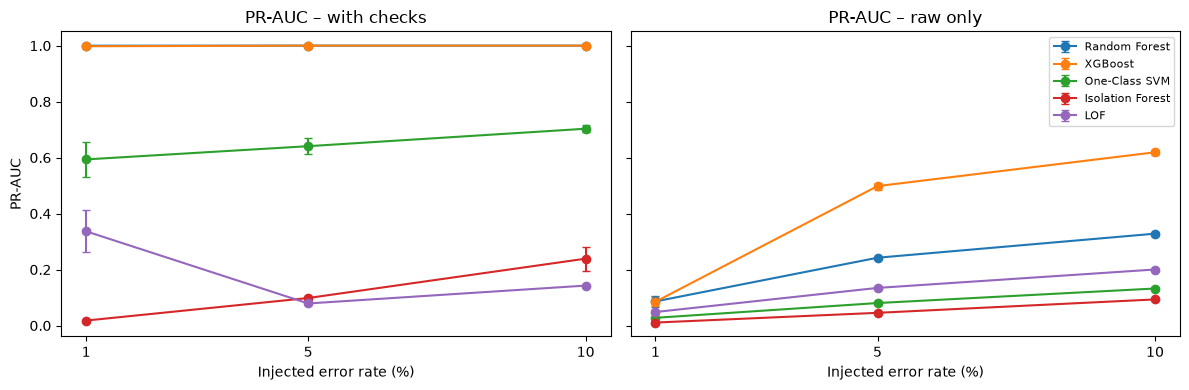

In [5]:
order = ['Random Forest', 'XGBoost', 'One-Class SVM', 'Isolation Forest', 'LOF']
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, fs in zip(axes, ['with checks', 'raw only']):
    sub = results[results.features == fs]
    for m in order:
        g = sub[sub.model == m].groupby('error_rate')['PR-AUC']
        ax.errorbar(g.mean().index * 100, g.mean(), yerr=g.std(), marker='o', capsize=3, label=m)
    ax.set(title=f'PR-AUC – {fs}', xlabel='Injected error rate (%)', xticks=[1, 5, 10])
axes[0].set_ylabel('PR-AUC'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(config.RESULTS / 'experiment_pr_auc_by_rate.png', dpi=150); plt.show()

## 5. Contribution of the check features (with checks − raw only)

In [6]:
gain = (results.pivot_table(index=['model', 'error_rate', 'seed'], columns='features', values='PR-AUC')
        .eval('gain = `with checks` - `raw only`').groupby(['model', 'error_rate'])['gain'].agg(['mean', 'std']).round(3))
gain.unstack('error_rate')

mean                  std              
error_rate         0.01   0.05   0.10   0.01   0.05   0.10
model                                                     
Isolation Forest  0.007  0.053  0.146  0.003  0.007  0.042
LOF               0.288 -0.056 -0.057  0.076  0.005  0.002
One-Class SVM     0.566  0.560  0.571  0.060  0.022  0.009
Random Forest     0.914  0.758  0.672  0.021  0.003  0.008
XGBoost           0.913  0.502  0.381  0.015  0.012  0.009

## 6. Which error types each model finds (recall by error type, averaged over all 9 datasets)

In [7]:
rec = pd.concat([pd.read_csv(OUT / f'recall_by_issue_{config.dataset_tag(r, s)}.csv', index_col=0)
                 for r in config.RATES for s in config.SEEDS])
rec_mean = rec.groupby(level=0).mean().round(2)
rec_mean = rec_mean.rename(columns={'none': 'false-alarm rate (none)'})
rec_mean.to_csv(config.RESULTS / 'experiment_recall_by_issue.csv')
rec_mean

,balance,categorical,crossfield,duplicate,missing,false-alarm rate (none),numerical
Isolation Forest | raw only,0.05,0.02,0.05,0.05,0.03,0.05,0.09
Isolation Forest | with checks,0.08,0.07,0.18,0.23,0.06,0.05,0.27
LOF | raw only,0.04,0.07,0.40,0.03,0.11,0.05,0.49
LOF | with checks,0.04,0.26,0.07,0.09,0.38,0.05,0.47
One-Class SVM | raw only,0.05,0.03,0.06,0.04,0.03,0.05,0.52
One-Class SVM | with checks,0.02,1.00,0.97,0.62,1.00,0.02,0.57
Random Forest | raw only,0.00,0.00,0.02,0.00,0.02,0.01,0.49
Random Forest | with checks,1.00,1.00,1.00,1.00,0.96,0.00,1.00
XGBoost | raw only,0.01,0.60,0.32,0.01,0.56,0.02,0.80
XGBoost | with checks,1.00,1.00,1.00,1.00,1.00,0.00,1.00


In [9]:
results = pd.read_csv(config.RESULTS / 'experiment_all_runs.csv')    # reload if needed
by_seed = results.pivot_table(index=['features', 'model', 'error_rate'], columns='seed', values='PR-AUC').round(3)
by_seed['mean'] = by_seed[[42, 7, 123]].mean(axis=1).round(3)
by_seed['range (max-min)'] = (by_seed[[42, 7, 123]].max(axis=1) - by_seed[[42, 7, 123]].min(axis=1)).round(3)
by_seed.to_csv(config.RESULTS / 'experiment_pr_auc_by_seed.csv')
by_seed

seed                                         7     42    123   mean  \
features    model            error_rate                               
raw only    Isolation Forest 0.01        0.011  0.011  0.011  0.011   
                             0.05        0.044  0.046  0.046  0.045   
                             0.10        0.094  0.094  0.092  0.093   
            LOF              0.01        0.055  0.048  0.042  0.048   
                             0.05        0.143  0.132  0.129  0.135   
                             0.10        0.201  0.202  0.198  0.200   
            One-Class SVM    0.01        0.031  0.028  0.024  0.028   
                             0.05        0.081  0.073  0.087  0.080   
                             0.10        0.129  0.131  0.137  0.132   
            Random Forest    0.01        0.106  0.088  0.065  0.086   
                             0.05        0.245  0.238  0.244  0.242   
                             0.10        0.333  0.332  0.319  0.328   
            XGBoost          0.01        0.105  0.075  0.076  0.085   
                             0.05        0.509  0.485  0.501  0.498   
                             0.10        0.613  0.629  0.615  0.619   
with checks Isolation Forest 0.01        0.016  0.016  0.021  0.018   
                             0.05        0.103  0.091  0.101  0.098   
                             0.10        0.289  0.218  0.210  0.239   
            LOF              0.01        0.372  0.250  0.388  0.337   
                             0.05        0.083  0.082  0.072  0.079   
                             0.10        0.143  0.146  0.139  0.143   
            One-Class SVM    0.01        0.599  0.653  0.529  0.594   
                             0.05        0.660  0.609  0.654  0.641   
                             0.10        0.699  0.694  0.717  0.703   
            Random Forest    0.01        0.999  1.000  1.000  1.000   
                             0.05        1.000  1.000  1.000  1.000   
                             0.10        1.000  1.000  1.000  1.000   
            XGBoost          0.01        1.000  0.994  1.000  0.998   
                             0.05        1.000  1.000  1.000  1.000   
                             0.10        1.000  1.000  1.000  1.000   

seed                                     range (max-min)  
features    model            error_rate                   
raw only    Isolation Forest 0.01                  0.000  
                             0.05                  0.002  
                             0.10                  0.002  
            LOF              0.01                  0.013  
                             0.05                  0.014  
                             0.10                  0.004  
            One-Class SVM    0.01                  0.007  
                             0.05                  0.014  
                             0.10                  0.008  
            Random Forest    0.01                  0.041  
                             0.05                  0.007  
                             0.10                  0.014  
            XGBoost          0.01                  0.030  
                             0.05                  0.024  
                             0.10                  0.016  
with checks Isolation Forest 0.01                  0.005  
                             0.05                  0.012  
                             0.10                  0.079  
            LOF              0.01                  0.138  
                             0.05                  0.011  
                             0.10                  0.007  
            One-Class SVM    0.01                  0.124  
                             0.05                  0.051  
                             0.10                  0.023  
            Random Forest    0.01                  0.001  
                             0.05                  0.000  
                             0.10                  0.000  
            XGBo

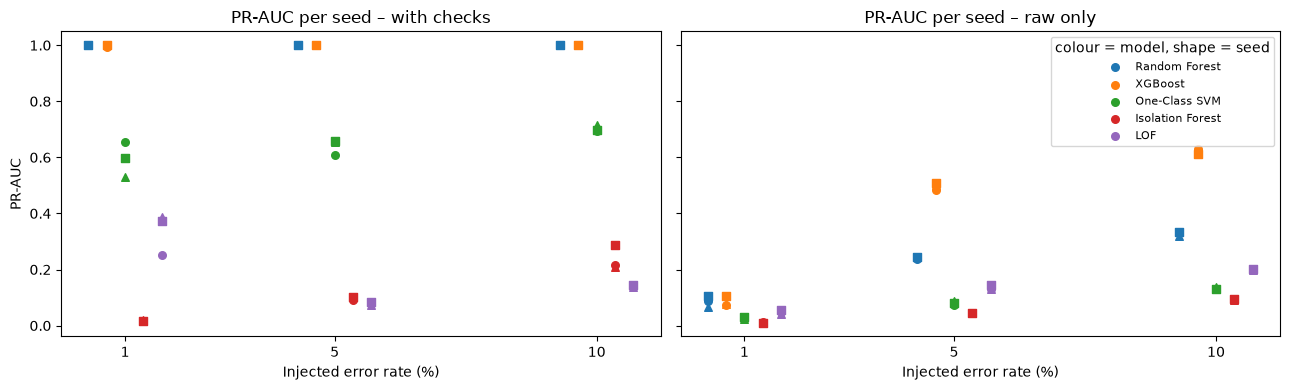

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
markers = {42: 'o', 7: 's', 123: '^'}
for ax, fs in zip(axes, ['with checks', 'raw only']):
    sub = results[results.features == fs]
    for i, m in enumerate(order):
        for seed, mk in markers.items():
            s = sub[(sub.model == m) & (sub.seed == seed)].sort_values('error_rate')
            ax.scatter(s.error_rate * 100 + (i - 2) * 0.35, s['PR-AUC'], marker=mk, s=30,
                       color=f'C{i}', label=f'{m}' if seed == 42 else None)
    ax.set(title=f'PR-AUC per seed – {fs}', xlabel='Injected error rate (%)', xticks=[1, 5, 10])
axes[0].set_ylabel('PR-AUC'); axes[1].legend(fontsize=8, title='colour = model, shape = seed')
plt.tight_layout(); plt.savefig(config.RESULTS / 'experiment_pr_auc_per_seed.png', dpi=150); plt.show()

## 7. Laundering false-alarm check
Share of the 1,411 excluded money-laundering transactions that each trained model flags as a data-quality error (mean ± SD over the 9 datasets). They contain no injected errors, so every flag is a false alarm on a genuine but unusual transaction.

In [8]:
laund_rate = (results.groupby(['features', 'model'])['extra_flag_rate'].agg(['mean', 'std']).round(3)
              .rename(columns={'mean': 'laundering flagged (mean)', 'std': 'SD'}))
laund_rate.to_csv(config.RESULTS / 'experiment_laundering_false_alarms.csv')
laund_rate

laundering flagged (mean)     SD
features    model                                             
raw only    Isolation Forest                      0.320  0.134
            LOF                                   0.528  0.136
            One-Class SVM                         0.326  0.063
            Random Forest                         0.254  0.210
            XGBoost                               0.586  0.361
with checks Isolation Forest                      0.382  0.138
            LOF                                   0.575  0.193
            One-Class SVM                         0.210  0.028
            Random Forest                         0.041  0.000
            XGBoost                               0.041  0.000

## Notes for the paper
- **Main results table:** section 3 (mean ± SD of PR-AUC by model, feature set and error rate).
- **Figure:** `results/experiment_pr_auc_by_rate.png`.
- **Check-feature contribution:** section 5; a large positive gain means the domain rules, not the model alone, drive detection.
- **Error types:** section 6 shows which errors are only detectable with check features (in the baseline, balance and duplicate errors).
- **Laundering check:** section 7 (false alarms on genuine but unusual transactions).
- **Stability across seeds:** the SD columns; small values mean the conclusions do not depend on one particular corruption.